<a href="https://colab.research.google.com/github/Hypefull/fraud_return/blob/main/GITHUBAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
from datasets import load_dataset

ds = load_dataset("sarveshchhetri/E-commerce_return_abuse_detection_dataset")

print("Hello")

Hello


In [4]:
import pandas as pd
import numpy as np

# Convert dataset to pandas DataFrame
# Usually Hugging Face datasets default to a 'train' split if not specified
split_name = list(ds.keys())[0] if isinstance(ds, dict) else 'train'
df = pd.DataFrame(ds[split_name])

# Define our features
features = [
    'return_rate_pct',
    'total_returns_lifetime',
    'customer_support_contacts',
    'days_to_return',
    'previous_dispute_count',
    'wishlist_to_cart_time_hrs',
    'tracking_number_valid',
    'refund_amount_requested_usd',
    'avg_order_value_usd',
    'total_orders_lifetime'
]

# Identify the target column
target_col = None
possible_targets = ['fraudulent_return', 'is_fraudulent', 'is_fraud', 'fraud_label', 'label']
for col in possible_targets:
    if col in df.columns:
        target_col = col
        break

if target_col is None:
    # Fallback search for columns containing 'fraud' or 'return_abuse'
    fraud_cols = [c for c in df.columns if 'fraud' in c.lower() or 'abuse' in c.lower()]
    if fraud_cols:
        target_col = fraud_cols[0]
    else:
        # Defaulting to 'label' column if present, otherwise using last column
        target_col = 'label' if 'label' in df.columns else df.columns[-1]

print(f"Selected Target Column: {target_col}")

# Keep only the requested columns and target
# We will handle potential missing columns gracefully
selected_columns = [col for col in features if col in df.columns]
missing_cols = set(features) - set(selected_columns)
if missing_cols:
    print(f"Warning: The following requested columns were not found in the dataset: {missing_cols}")

X = df[selected_columns].copy()
y = df[target_col].copy()

display(X.head())

Selected Target Column: abuse_type


,return_rate_pct,total_returns_lifetime,customer_support_contacts,days_to_return,previous_dispute_count,wishlist_to_cart_time_hrs,tracking_number_valid,refund_amount_requested_usd,avg_order_value_usd,total_orders_lifetime
0,1.2,1,1,15,0,70.5,1,254.92,258.77,80
1,3.7,2,0,30,0,25.3,1,84.11,93.63,54
2,0.0,0,0,14,0,36.6,1,95.58,95.66,43
3,69.4,25,3,4,0,4.4,1,447.99,464.47,36
4,0.0,0,1,5,1,40.9,1,112.12,138.01,59


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Preprocess Boolean/Categorical features among selected features (e.g. tracking_number_valid)
for col in X.columns:
    if X[col].dtype == 'object' or X[col].dtype == 'bool':
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))

# Handle missing values if any
X = X.fillna(X.median(numeric_only=True))

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Print metrics
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== Accuracy Score ===")
print(f"{accuracy_score(y_test, y_pred):.4f}")

=== Classification Report ===
                   precision    recall  f1-score   support

Fraudulent Return       1.00      1.00      1.00      1223
       Legitimate       1.00      1.00      1.00      8412
    Policy Abuser       1.00      1.00      1.00      1438
       Wardrobing       1.00      1.00      1.00       927

         accuracy                           1.00     12000
        macro avg       1.00      1.00      1.00     12000
     weighted avg       1.00      1.00      1.00     12000

=== Accuracy Score ===
0.9996


In [6]:
# Map the multi-class labels to binary 'Fraudulent' or 'Legitimate'
binary_map = {
    'Fraudulent Return': 'Fraudulent',
    'Policy Abuser': 'Fraudulent',
    'Wardrobing': 'Fraudulent',
    'Legitimate': 'Legitimate'
}

y_binary = y.map(binary_map)

# Split the dataset again using the simplified binary target
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

# Retrain the model on binary targets
binary_model = RandomForestClassifier(n_estimators=100, random_state=42)
binary_model.fit(X_train_bin, y_train_bin)

# Evaluate the model
y_pred_bin = binary_model.predict(X_test_bin)
print("=== Binary Classification Report ===")
print(classification_report(y_test_bin, y_pred_bin))

print("=== Accuracy Score ===")
print(f"{accuracy_score(y_test_bin, y_pred_bin):.4f}")

=== Binary Classification Report ===
              precision    recall  f1-score   support

  Fraudulent       1.00      1.00      1.00      3588
  Legitimate       1.00      1.00      1.00      8412

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000

=== Accuracy Score ===
1.0000


/tmp/ipykernel_1386/3140805629.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=X.columns[indices], palette='viridis')


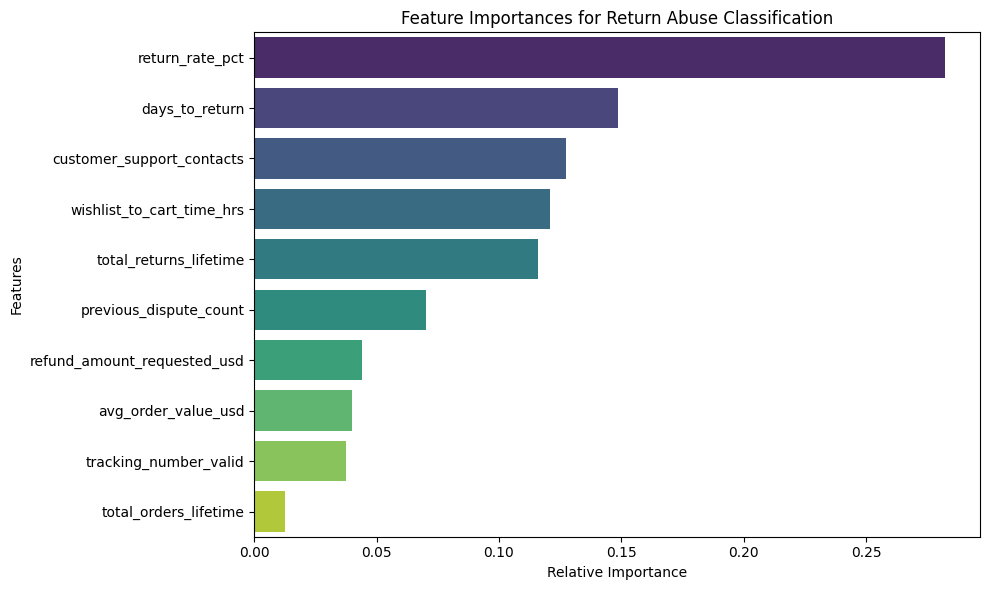

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=X.columns[indices], palette='viridis')
plt.title('Feature Importances for Return Abuse Classification')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [11]:
# Reconstruct a dataframe for the test subset using the binary labels and predictions
comparison_df_bin = X_test_bin.copy()

# Add actual and predicted binary labels to the visualization
comparison_df_bin['Actual_Binary_Status'] = y_test_bin
comparison_df_bin['Predicted_Binary_Status'] = y_pred_bin

# Display a random sample of 10 transactions to compare actuals vs predictions
display(comparison_df_bin.sample(n=10, random_state=42))

,return_rate_pct,total_returns_lifetime,customer_support_contacts,days_to_return,previous_dispute_count,wishlist_to_cart_time_hrs,tracking_number_valid,refund_amount_requested_usd,avg_order_value_usd,total_orders_lifetime,Actual_Binary_Status,Predicted_Binary_Status
41531,0.0,0,1,12,0,69.6,1,162.54,164.18,10,Legitimate,Legitimate
48188,11.1,4,0,23,0,7.0,1,137.94,162.62,36,Legitimate,Legitimate
13679,6.6,4,1,5,0,49.2,1,198.77,223.13,61,Legitimate,Legitimate
35299,9.1,3,0,7,0,22.0,1,22.79,23.55,33,Legitimate,Legitimate
57920,56.1,23,1,1,5,4.5,1,563.86,552.49,41,Fraudulent,Fraudulent
12106,8.6,3,1,6,1,30.8,1,229.22,278.91,35,Legitimate,Legitimate
33045,10.4,5,1,3,1,69.0,1,153.43,180.74,48,Legitimate,Legitimate
47243,11.8,6,0,20,1,57.8,1,208.72,221.47,51,Legitimate,Legitimate
37861,77.4,41,3,2,1,36.9,1,174.68,179.38,53,Fraudulent,Fraudulent
56502,2.3,1,1,24,1,47.7,1,272.09,281.57,43,Legitimate,Legitimate


In [9]:
import joblib

# Save the model to a file
model_filename = 'return_abuse_detector_model.joblib'
joblib.dump(model, model_filename)

print(f"Model successfully exported and saved to {model_filename}")

Model successfully exported and saved to return_abuse_detector_model.joblib
